# 4. Classification: MNIST

Handwritten digits, 28x28 pixels (784 inputs), 10 classes. Same setup as Iris: one-hot targets,
10 sigmoid outputs and Binary Cross-Entropy. The predicted digit is the output with the largest value.

The 60,000 training images are used for training and the 10,000 test images for validation.

In [1]:
import sys
sys.path.append("..")  # so we can import the code in src/

import numpy as np

from src.datasets import load_mnist
from src.nn import MLP
from src.optim import Adam
from src.training import train
from src.plots import plot_loss, plot_metric, plot_histograms

PLOTS = "../assets/plots/"

In [2]:
X_train, y_train, X_val, y_val = load_mnist()

print("train:", X_train.shape, y_train.shape)
print("val:  ", X_val.shape, y_val.shape)

train: (60000, 784) (60000, 10)
val:   (10000, 784) (10000, 10)


## Model and training

In [3]:
model = MLP(input_size=784, hidden_sizes=[128, 64], output_size=10,
            hidden_activation="relu", output_activation="sigmoid", init="he")

optimizer = Adam(model.parameters(), lr=0.001)

history = train(model, optimizer, "bce", X_train, y_train, X_val, y_val,
                epochs=10, batch_size=64, metric_name="accuracy", print_every=1)

epoch    1 | train loss 0.0310 | val loss 0.0320 | train accuracy 0.9553 | val accuracy 0.9515


epoch    2 | train loss 0.0183 | val loss 0.0209 | train accuracy 0.9739 | val accuracy 0.9694


epoch    3 | train loss 0.0129 | val loss 0.0169 | train accuracy 0.9827 | val accuracy 0.9754


epoch    4 | train loss 0.0106 | val loss 0.0160 | train accuracy 0.9856 | val accuracy 0.9754


epoch    5 | train loss 0.0075 | val loss 0.0139 | train accuracy 0.9902 | val accuracy 0.9799


epoch    6 | train loss 0.0069 | val loss 0.0148 | train accuracy 0.9914 | val accuracy 0.9777


epoch    7 | train loss 0.0057 | val loss 0.0141 | train accuracy 0.9936 | val accuracy 0.9797


epoch    8 | train loss 0.0039 | val loss 0.0130 | train accuracy 0.9958 | val accuracy 0.9814


epoch    9 | train loss 0.0034 | val loss 0.0142 | train accuracy 0.9969 | val accuracy 0.9815


epoch   10 | train loss 0.0037 | val loss 0.0165 | train accuracy 0.9954 | val accuracy 0.9790


## Monitoring

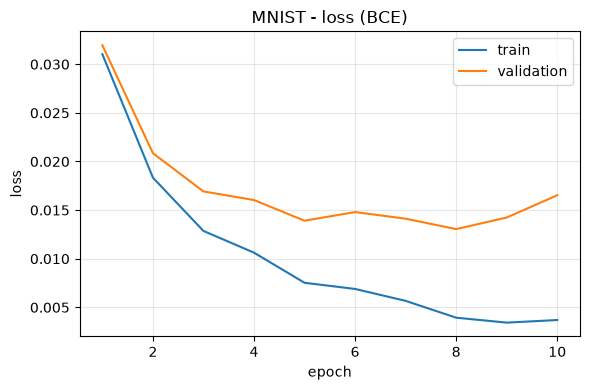

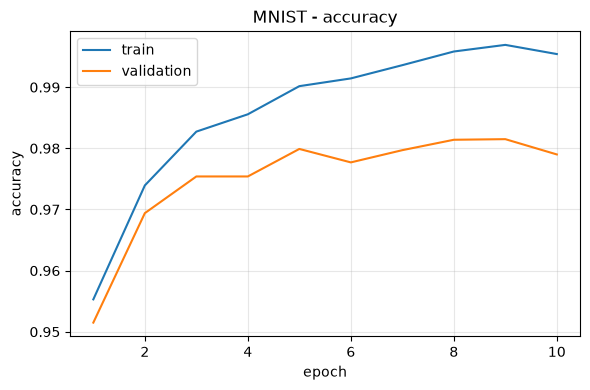

In [4]:
plot_loss(history, title="MNIST - loss (BCE)", save_path=PLOTS + "mnist_loss.png")
plot_metric(history, "accuracy", title="MNIST - accuracy", save_path=PLOTS + "mnist_accuracy.png")

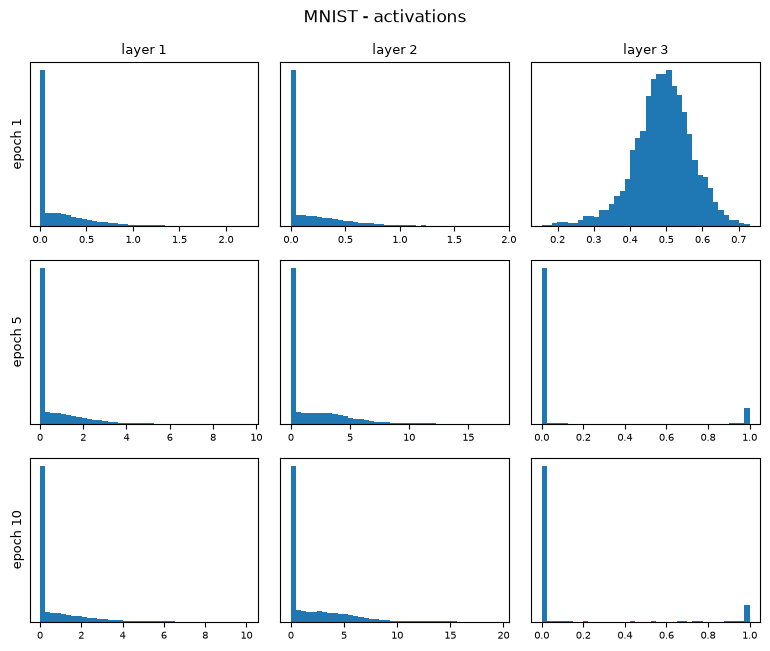

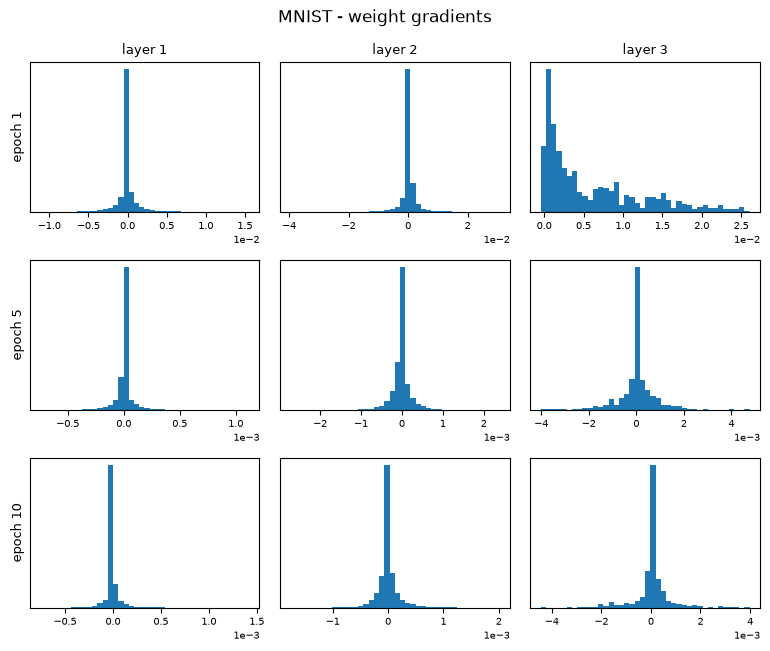

In [5]:
plot_histograms(history, "activations", title="MNIST - activations", save_path=PLOTS + "mnist_activations.png")
plot_histograms(history, "gradients", title="MNIST - weight gradients", save_path=PLOTS + "mnist_gradients.png")

## Export and import

In [6]:
model.save("../models/mnist_mlp.npz")

loaded_model = MLP.load("../models/mnist_mlp.npz")
predicted_digits = np.argmax(loaded_model.predict(X_val), axis=1)
true_digits = np.argmax(y_val, axis=1)
print("validation accuracy of the loaded model:", np.mean(predicted_digits == true_digits))

validation accuracy of the loaded model: 0.979
